# Lab 17 solution, notebook 2: a second chart with the rows handed to the code, and the container's limits

The worked answers to the two challenge tasks of `17b_code_execution_at_the_desk.ipynb`. The setup repeats what the
tasks need from the notebook (the read-only database, Part D's `run_sql`, the tools, the loop and the helpers; Part
E's flags and runner), so this file runs on its own. ⚠️ Task 1 starts one container session on OpenAI's side; Task 2
needs Docker and costs nothing.

## Setup

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


In [2]:
import base64
import csv
import io
import json
import re
import sqlite3
from IPython.display import Image, display
from openai import OpenAI, omit

client = OpenAI(timeout=120)

OUTPUTS = ROOT / "17_Code_Execution" / "solved" / "outputs"
OUTPUTS.mkdir(exist_ok=True)
conn = sqlite3.connect(f"file:{ROOT / 'data' / 'chinook.db'}?mode=ro", uri=True, check_same_thread=False)

CODE_INTERPRETER = {
    "type": "code_interpreter",
    "container": {"type": "auto", "memory_limit": "1g", "network_policy": {"type": "disabled"}},
}
RUN_SQL = {
    "type": "function",
    "name": "run_sql",
    "description": ("Run one read-only SQLite query on the Chinook music shop's database. The table invoices has "
                    "one row per sale, with InvoiceDate (text, 'YYYY-MM-DD HH:MM:SS') and Total (US dollars)."),
    "parameters": {"type": "object", "properties": {"query": {"type": "string"}},
                   "required": ["query"], "additionalProperties": False},
    "strict": True,
}
TOOLS = [RUN_SQL, CODE_INTERPRETER]
SYSTEM = ("You are the Chinook music shop's data assistant. Use run_sql to read the database and the python tool "
          "to draw charts. Show every chart with plt.show().")

Part D's `run_sql` (the rows go to the code as a file; the model gets only their shape), the loop of Part B, and the
helpers of Parts B and C, as they were in the notebook.

In [3]:
UPLOADED = []


def run_sql(query):
    """Run the query; upload all its rows as a CSV file for the code interpreter; tell the model only their shape."""
    try:
        cursor = conn.execute(query)
    except sqlite3.Error as error:
        return f"SQLite error: {error}"
    columns = [column[0] for column in cursor.description]
    rows = cursor.fetchall()
    text = io.StringIO()
    writer = csv.writer(text)
    writer.writerow(columns)
    writer.writerows(rows)
    uploaded = client.files.create(file=("query_result.csv", text.getvalue().encode()), purpose="user_data")
    UPLOADED.append(uploaded.id)
    CODE_INTERPRETER["container"]["file_ids"] = [uploaded.id]
    return (f"{len(rows)} rows, columns {', '.join(columns)}, saved for the python tool in /mnt/data "
            "as a CSV file whose name ends in query_result.csv.")


def ask_chart_agent(question, max_turns=6):
    """Send the question; run every run_sql call the model asks for; stop when a response asks for none."""
    response = client.responses.create(
        model=MODEL, reasoning={"effort": EFFORT or omit}, instructions=SYSTEM,
        input=question, tools=TOOLS, include=["code_interpreter_call.outputs"],
    )
    responses = [response]
    for turn in range(max_turns):
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            break
        outputs = [{"type": "function_call_output", "call_id": call.call_id,
                    "output": run_sql(json.loads(call.arguments)["query"])} for call in calls]
        response = client.responses.create(
            model=MODEL, reasoning={"effort": EFFORT or omit}, instructions=SYSTEM,
            previous_response_id=response.id, input=outputs, tools=TOOLS,
            include=["code_interpreter_call.outputs"],
        )
        responses.append(response)
    return responses


def show_run(responses):
    for number, response in enumerate(responses, 1):
        for item in response.output:
            if item.type == "function_call":
                print(f"call {number}  run_sql (our code):", json.loads(item.arguments)["query"].strip())
            elif item.type == "code_interpreter_call":
                kinds = [output.type for output in item.outputs or []]
                print(f"call {number}  code interpreter (OpenAI's container): {len(item.code.splitlines())} lines, outputs {kinds}")
            elif item.type == "message":
                print(f"call {number}  reply:", response.output_text)


def code_calls(responses):
    return [item for r in responses for item in r.output if item.type == "code_interpreter_call"]


def show_chart(responses, filename):
    images = [output for item in code_calls(responses) for output in item.outputs or [] if output.type == "image"]
    if not images:
        print("No chart came back: the code saved it in the container without showing it.")
        return
    png = base64.b64decode(images[-1].url.split(",", 1)[1])
    (OUTPUTS / filename).write_bytes(png)
    display(Image(data=png, width=600))

## Task 1: A second chart, with the rows handed to the code

First the answer the chart must show, from our own query: the five countries with the most revenue.

In [4]:
COUNTRY_SQL = """
SELECT BillingCountry AS country, ROUND(SUM(Total), 2) AS revenue
FROM invoices
GROUP BY country
ORDER BY revenue DESC
LIMIT 5
"""
TOP5 = dict(conn.execute(COUNTRY_SQL).fetchall())
print(TOP5)

{'USA': 523.06, 'Canada': 303.96, 'France': 195.1, 'Brazil': 190.1, 'Germany': 156.48}


Then the agent, with Part D's `run_sql` in place.

call 1  run_sql (our code): SELECT BillingCountry, SUM(Total) AS Revenue FROM invoices GROUP BY BillingCountry ORDER BY Revenue DESC LIMIT 5;
call 2  code interpreter (OpenAI's container): 3 lines, outputs ['logs']
call 2  code interpreter (OpenAI's container): 10 lines, outputs ['image']
call 2  reply: The bar chart shows the five highest-revenue countries. The USA leads with **$523.06**, followed by Canada at **$303.96**.


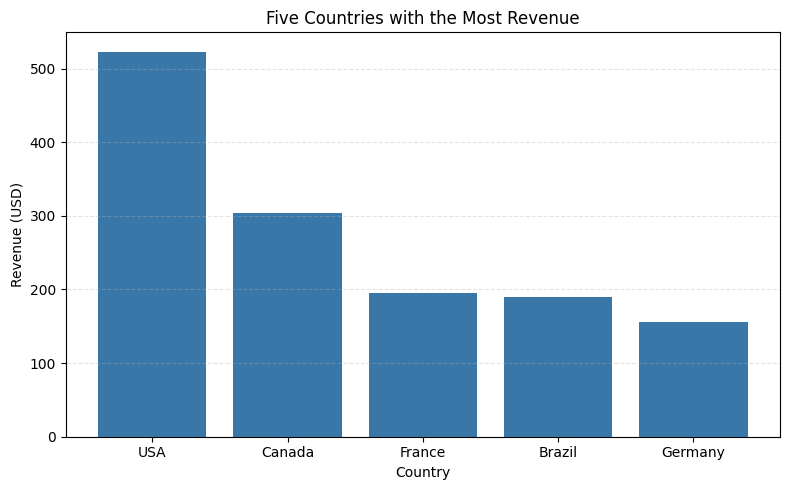

In [5]:
run_countries = ask_chart_agent("Make a bar chart of the five countries with the most revenue.")
show_run(run_countries)
show_chart(run_countries, "chart_countries.png")

In our run: one query, which our code ran and uploaded (the model's own query, `SUM(Total)` without rounding); then two pieces of code, one that loaded the file and printed it, and one that drew the chart. The reply names the USA at $523.06 and Canada at $303.96, which match `TOP5`. All the code the model wrote, and the same check as Part C, now against the five country totals:

In [6]:
all_code = "\n".join(call.code for call in code_calls(run_countries))
print(all_code)

typed = {round(float(number), 2) for number in re.findall(r"\d+\.\d+", all_code)}
print("country totals typed in:", sum(revenue in typed for revenue in TOP5.values()), "of 5")

import pandas as pd
df = pd.read_csv('/mnt/data/file-V4eBm6gV2e5Us8fvBVWJ7Z-query_result.csv')
df

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(df['BillingCountry'], df['Revenue'], color='#3977A8')
plt.title('Five Countries with the Most Revenue')
plt.xlabel('Country')
plt.ylabel('Revenue (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

country totals typed in: 0 of 5


The code reads the file and draws its two columns, `BillingCountry` and `Revenue`: `country totals typed in: 0 of 5`, and the highest bar is the USA.

Delete the uploaded files.

In [7]:
for file_id in UPLOADED:
    client.files.delete(file_id)
print("deleted", len(UPLOADED), "uploaded files")
UPLOADED.clear()
del CODE_INTERPRETER["container"]["file_ids"]

deleted 1 uploaded files


## Task 2: Test the container's limits

This task needs Docker; without it every cell prints a skip line. The image, the flags and `run_in_container` are
Part E's.

In [8]:
import shutil
import subprocess

SKIP = "Docker is not available: skipped. The saved output shows our run."
DOCKER_OK = shutil.which("docker") is not None and subprocess.run(["docker", "info"], capture_output=True).returncode == 0

SANDBOX_FLAGS = [
    "--rm", "--network", "none", "--read-only", "--tmpfs", "/tmp",
    "--memory", "256m", "--memory-swap", "256m", "--cpus", "1", "--pids-limit", "64",
    "--cap-drop", "ALL", "--security-opt", "no-new-privileges",
]
OUTPUTS.chmod(0o777)
MOUNT = ["--volume", f"{OUTPUTS}:/work"]


def run_in_container(code):
    """Run Python code in a new sandbox container; return what it printed."""
    (OUTPUTS / "run.py").write_text(code)
    result = subprocess.run(
        ["docker", "run", *SANDBOX_FLAGS, *MOUNT, "chinook-sandbox", "timeout", "20", "python", "run.py"],
        capture_output=True, text=True,
    )
    printed = result.stdout + result.stderr
    return printed or f"finished with exit code {result.returncode}, printed nothing"


if DOCKER_OK:
    build = subprocess.run(["docker", "build", "--quiet", "--tag", "chinook-sandbox",
                            str(ROOT / "17_Code_Execution" / "resources")], capture_output=True, text=True)
    print("image built:", build.returncode == 0)
else:
    print(SKIP)

image built: True


The endless loop first. It never prints anything, so whatever stops it, the result is the runner's exit-code line.

In [9]:
if DOCKER_OK:
    print(run_in_container("while True:\n    pass\n"))
else:
    print(SKIP)

finished with exit code 124, printed nothing


`finished with exit code 124, printed nothing`. 124 is the exit code the `timeout` program gives when it stops a command: after 20 seconds, `timeout 20` stopped the loop, and the container ended with it.

Then 300 MB in one bytes object, more than the 256 MB the container may use.

In [10]:
if DOCKER_OK:
    print(run_in_container("data = b'x' * (300 * 1024 * 1024)\nprint('built', len(data))\n"))
else:
    print(SKIP)

finished with exit code 137, printed nothing


`finished with exit code 137, printed nothing`. 137 is 128 + 9: the process was stopped by signal 9 (kill). The kernel stopped the code when it went past the 256 MB that `--memory 256m` allows, and `--memory-swap 256m` left no swap space to borrow on top. The `print` line never ran.